In [ ]:
# Step 1: Import the Iris dataset
from sklearn.datasets import load_iris

# Step 2: Load the dataset
iris = load_iris()

# Step 3: Display information
print("Iris Dataset Loaded Successfully!")

print("\nFeatures:")
print(iris.feature_names)

print("\nFlower Species:")
print(iris.target_names)

print("\nTotal Flowers:")
print(len(iris.data))

Iris Dataset Loaded Successfully!

Features:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Flower Species:
['setosa' 'versicolor' 'virginica']

Total Flowers:
150


In [ ]:

# Import pandas library
import pandas as pd

# Convert the Iris dataset into a DataFrame
df = pd.DataFrame(iris.data, columns=iris.feature_names)

# Add flower species to the dataset
df['species'] = iris.target

# Display the first five rows
print("First Five Rows of the Dataset:")
display(df.head())


First Five Rows of the Dataset:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [ ]:

# Check the dataset dimensions
print("Dataset Shape:")
print(df.shape)

# Check column information
print("\nDataset Information:")
df.info()

# Check statistical summary
print("\nStatistical Summary:")
display(df.describe())


Dataset Shape:
(150, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 6.0 KB

Statistical Summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


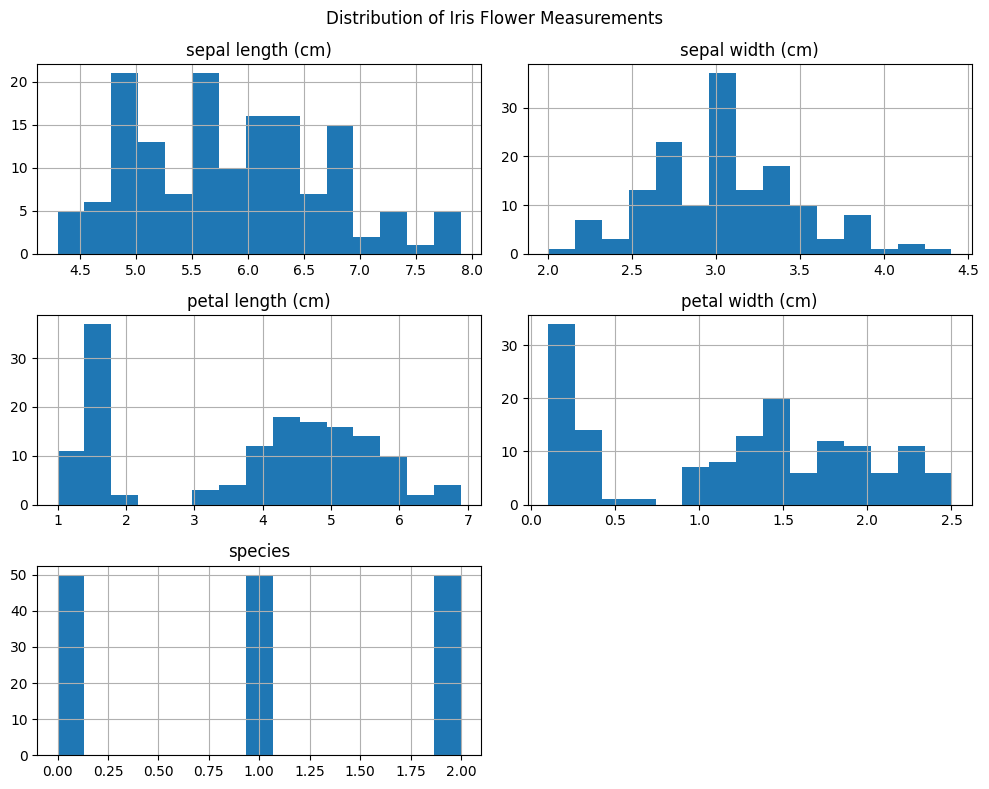

In [ ]:

# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Create a histogram for all flower measurements
df.hist(figsize=(10, 8), bins=15)

# Add a title
plt.suptitle("Distribution of Iris Flower Measurements")

# Display graphs
plt.tight_layout()
plt.show()


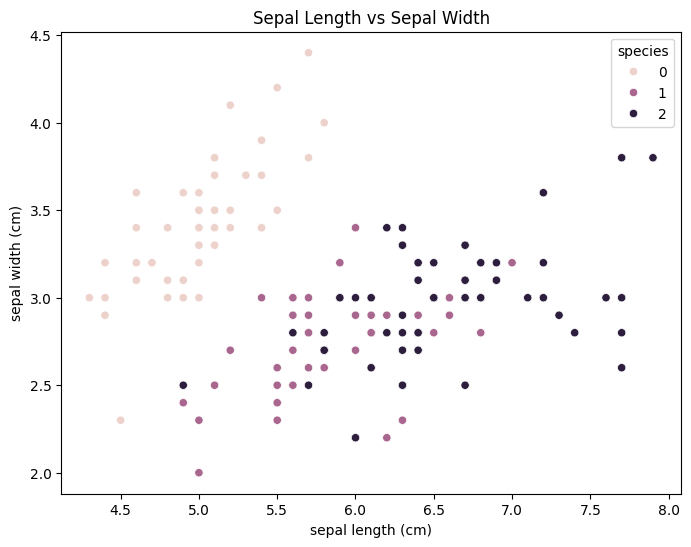

In [ ]:
# Create a scatter plot
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='sepal length (cm)',
    y='sepal width (cm)',
    hue='species'
)

plt.title("Sepal Length vs Sepal Width")
plt.show()

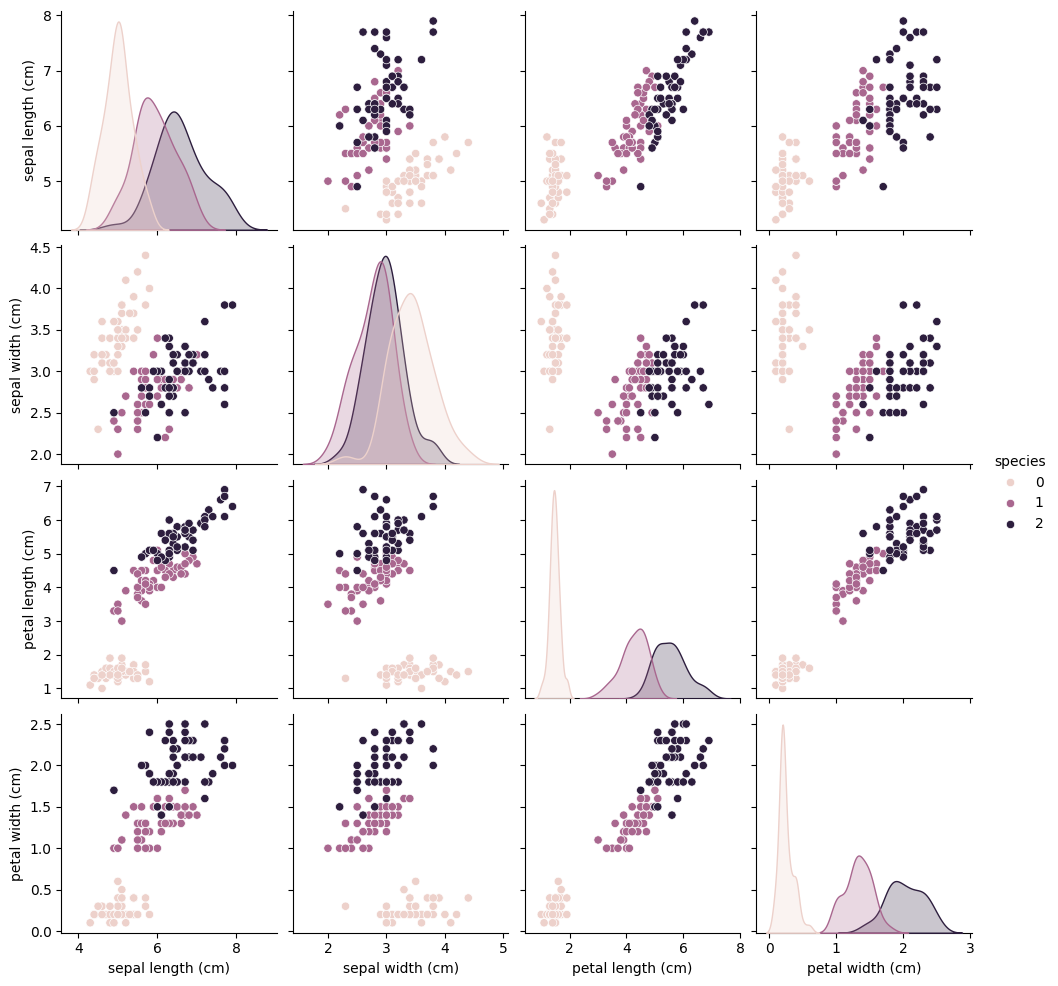

In [ ]:
# Create a pair plot
sns.pairplot(df, hue='species')

# Display the graph
plt.show()

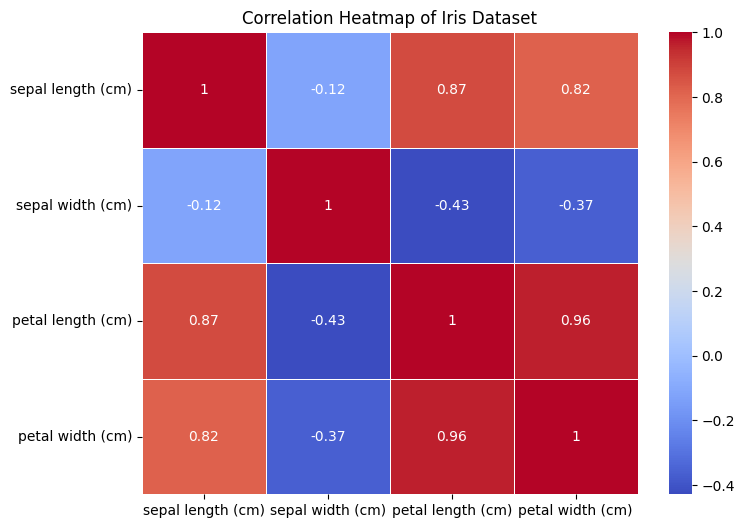

In [ ]:
# Calculate correlation between numerical columns
correlation = df.drop(columns=['species']).corr()

# Create heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    linewidths=0.5
)

plt.title("Correlation Heatmap of Iris Dataset")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [ ]:
# Separate input features and target

X = df.drop('species', axis=1)

y = df['species']

print("Input features:")
print(X.head())

print("\nTarget output:")
print(y.head())

Input features:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Target output:
0    0
1    0
2    0
3    0
4    0
Name: species, dtype: int64


In [ ]:
# Split dataset into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [ ]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (120, 4)
Testing data: (30, 4)


In [ ]:
# Create the Logistic Regression model
model = LogisticRegression(max_iter=200)

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [ ]:
# Predict flower species using test data

y_pred = model.predict(X_test)

print("Predicted values:")
print(y_pred)

print("\nActual values:")
print(y_test.values)

Predicted values:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]

Actual values:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]


In [ ]:
# Calculate model accuracy

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 100.0 %


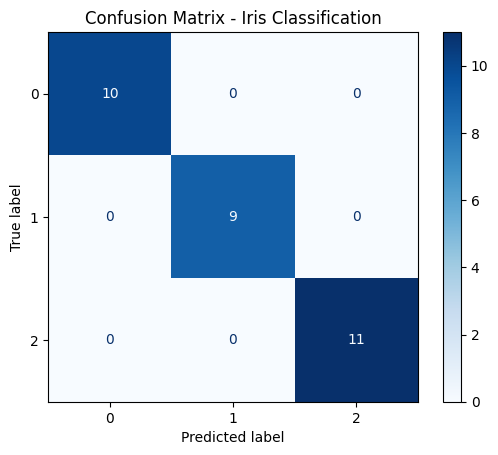

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(confusion_matrix=cm)

display.plot(cmap='Blues')
plt.title("Confusion Matrix - Iris Classification")
plt.show()

In [ ]:
# Import classification report
from sklearn.metrics import classification_report

# Generate classification report
report = classification_report(y_test, y_pred)

# Display report
print(report)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [1]:
# Import machine learning algorithms

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Import evaluation metric
from sklearn.metrics import accuracy_score

print("All algorithms imported successfully!")

All algorithms imported successfully!


In [2]:
# Create five machine learning models

models = {
    "Logistic Regression": LogisticRegression(max_iter=200),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC()
}

print("Five models created successfully!")

Five models created successfully!


In [3]:
# Train and evaluate all models

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    results.append({
        "Model": name,
        "Accuracy": accuracy * 100
    })

# Convert results into a table
results_df = pd.DataFrame(results)

print(results_df)

NameError: name 'X_train' is not defined

In [4]:
from sklearn.datasets import load_iris
import pandas as pd

# Load Iris dataset
iris = load_iris()

# Create DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add target column
df['species'] = iris.target

print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   species  
0        0  
1        0  
2        0  
3        0  
4        0  


In [5]:
X = df.drop('species', axis=1)

y = df['species']

print("Dataset separated successfully!")

Dataset separated successfully!


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (120, 4)
Testing data: (30, 4)


In [7]:
# Train and compare all five models

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    results.append({
        "Model": name,
        "Accuracy": accuracy * 100
    })

# Create comparison table
results_df = pd.DataFrame(results)

print(results_df)

                 Model  Accuracy
0  Logistic Regression     100.0
1        Decision Tree     100.0
2        Random Forest     100.0
3                  KNN     100.0
4                  SVM     100.0


In [8]:
from sklearn.model_selection import cross_val_score

print("Cross-validation library imported successfully!")

Cross-validation library imported successfully!


In [9]:
# Perform 5-fold cross-validation

cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X,
        y,
        cv=5,
        scoring='accuracy'
    )

    cv_results.append({
        "Model": name,
        "Mean Accuracy": scores.mean() * 100,
        "Standard Deviation": scores.std() * 100
    })

# Display results
cv_df = pd.DataFrame(cv_results)

print(cv_df.round(2))

                 Model  Mean Accuracy  Standard Deviation
0  Logistic Regression          97.33                2.49
1        Decision Tree          95.33                3.40
2        Random Forest          96.67                2.11
3                  KNN          97.33                2.49
4                  SVM          96.67                2.11


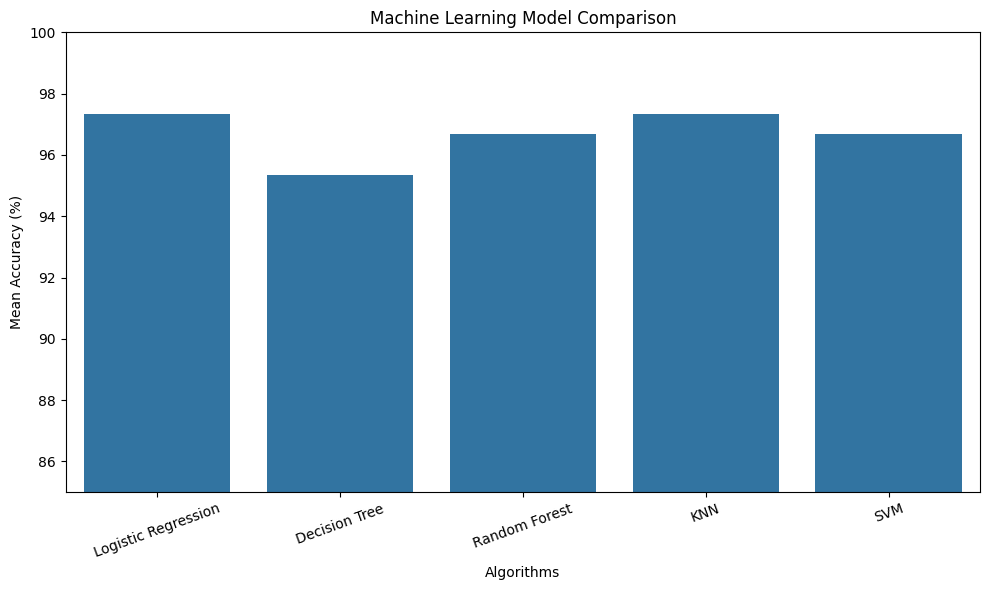

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=cv_df,
    x='Model',
    y='Mean Accuracy'
)

plt.title("Machine Learning Model Comparison")
plt.xlabel("Algorithms")
plt.ylabel("Mean Accuracy (%)")

plt.xticks(rotation=20)
plt.ylim(85, 100)

plt.tight_layout()
plt.show()

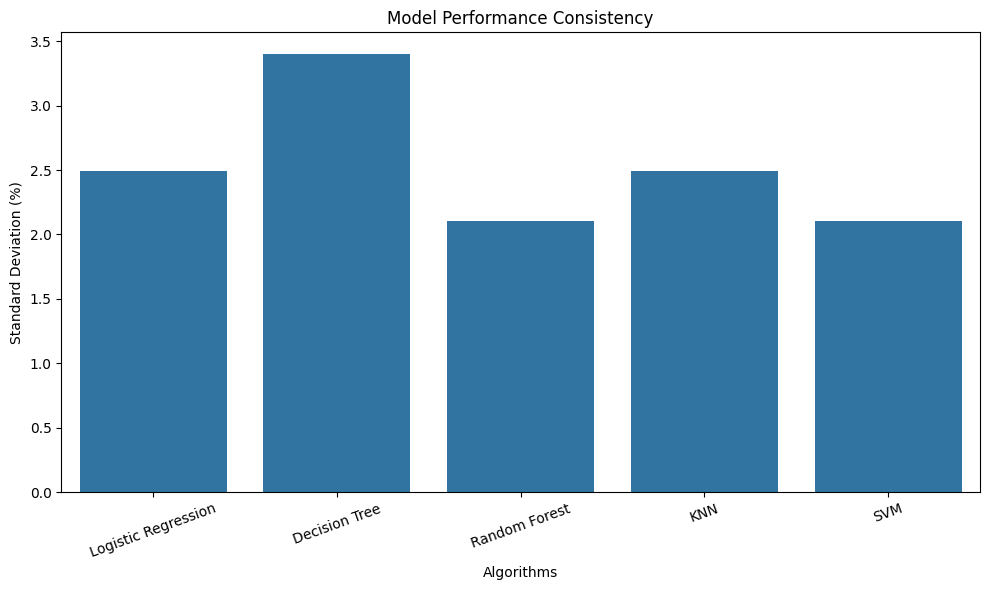

In [11]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=cv_df,
    x='Model',
    y='Standard Deviation'
)

plt.title("Model Performance Consistency")
plt.xlabel("Algorithms")
plt.ylabel("Standard Deviation (%)")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [12]:
# Train Random Forest model

rf_model = RandomForestClassifier(random_state=42)

rf_model.fit(X_train, y_train)

# Calculate feature importance

importance = rf_model.feature_importances_

# Create feature importance table

feature_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance
})

feature_df = feature_df.sort_values(
    by='Importance',
    ascending=False
)

print(feature_df)

             Feature  Importance
2  petal length (cm)    0.439994
3   petal width (cm)    0.421522
0  sepal length (cm)    0.108098
1   sepal width (cm)    0.030387


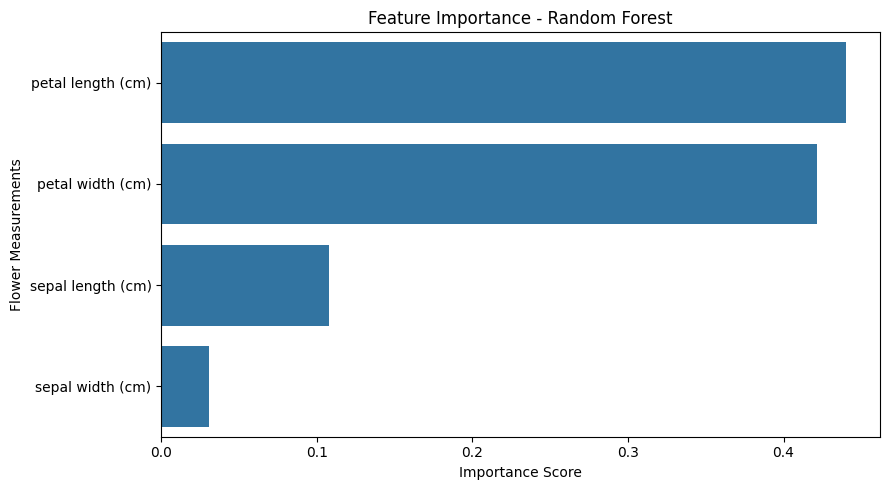

In [13]:
# Plot feature importance

plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_df,
    x='Importance',
    y='Feature'
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Flower Measurements")

plt.tight_layout()
plt.show()

In [14]:
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

importance = rf_model.feature_importances_

feature_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance
})

feature_df = feature_df.sort_values(
    by='Importance', ascending=False
)

print(feature_df)

             Feature  Importance
2  petal length (cm)    0.439994
3   petal width (cm)    0.421522
0  sepal length (cm)    0.108098
1   sepal width (cm)    0.030387


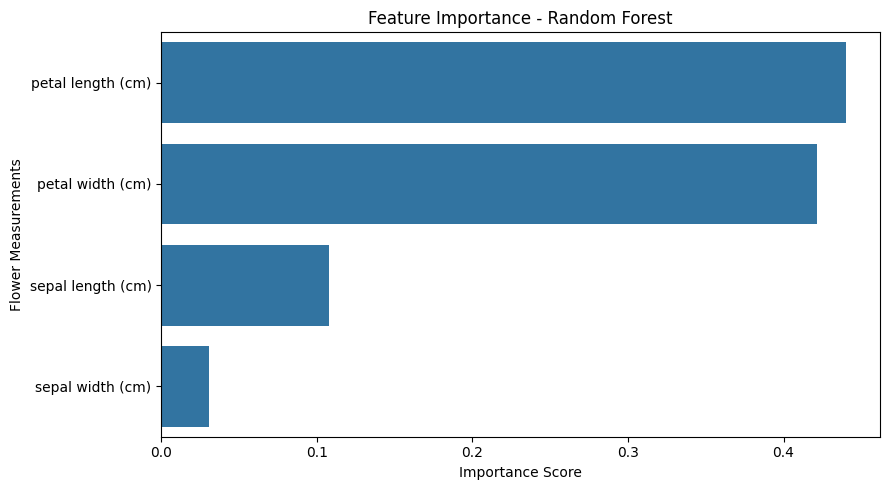

In [15]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_df,
    x='Importance',
    y='Feature'
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Flower Measurements")

plt.tight_layout()
plt.show()